# SAP-DCG: Comprehensive Synthetic Dataset Evaluation Metrics (CTGAN vs. TVAE)

This notebook computes and plots **representative metrics from every category** in [`docs/synthetic_evaluation_metrics_reference.md`](../docs/synthetic_evaluation_metrics_reference.md) and [`docs/ids_generative_metrics_summary-v2.xlsx`](../docs/ids_generative_metrics_summary-v2.xlsx), aligned with [`docs/statistics evaluation.txt`](../docs/statistics%20evaluation.txt) (**Reliability**, **Security**, **Balance**, and **Numerical Statistical Methods**).

### Evaluated Artifacts (Latest Runs)
- **CTGAN (`result_2`):** `results/ctgan/result_2/synthetic_samples_kept.csv` (`429` filtered synthetic attack flows, `best_y_max=25`), `unsw_nb15_final_pipeline_train.csv` (`690,657` rows), `pipeline_tuning_summary.json`
- **TVAE (`result_2`):** `results/tvae/result_2/synthetic_samples_kept.csv` (`21,567` filtered synthetic attack flows across 7 minority classes, `best_y_max=30`), `unsw_nb15_final_pipeline_train.csv` (`711,795` rows), `pipeline_tuning_summary.json`, and 7 per-class `TVAESynthesizer` models
- **Reference Real Splits:** `dataset/dev_splits/NF-UNSW-NB15-v3_train.csv`, `NF-UNSW-NB15-v3_test.csv`, `dataset/holdout_set/NF-UNSW-NB15-v3.csv`, and `dataset/synthetic_deficit.json`

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.spatial.distance import jensenshannon
from scipy.stats import anderson_ksamp, chi2_contingency, ks_2samp, spearmanr, wasserstein_distance
from sklearn.decomposition import PCA
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import f1_score, precision_recall_fscore_support, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_sample_weight

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
SEED = 42
rng = np.random.default_rng(SEED)

# Resolve SAP-DCG root cleanly whether launched from notebooks/ or SAP-DCG/
cwd = Path(".").resolve()
ROOT = cwd.parent if cwd.name == "notebooks" else (cwd / "SAP-DCG" if (cwd / "SAP-DCG").exists() else cwd)
print("SAP-DCG Root:", ROOT)

CATEGORICAL_FEATURES = [
    "PROTOCOL", "L7_PROTO", "TCP_FLAGS", "CLIENT_TCP_FLAGS",
    "SERVER_TCP_FLAGS", "ICMP_TYPE", "ICMP_IPV4_TYPE",
    "DNS_QUERY_ID", "DNS_QUERY_TYPE", "DNS_TTL_ANSWER", "FTP_COMMAND_RET_CODE",
]
RARE_CLASSES = ["Analysis", "Backdoor", "Shellcode", "Worms"]

SAP-DCG Root: /run/media/thanh/Data/Project A/SAP-DCG


In [2]:
# Load real splits, synthetic outputs, and JSON summaries
train_df = pd.read_csv(ROOT / "dataset/dev_splits/NF-UNSW-NB15-v3_train.csv")
test_df = pd.read_csv(ROOT / "dataset/dev_splits/NF-UNSW-NB15-v3_test.csv")
holdout_df = pd.read_csv(ROOT / "dataset/holdout_set/NF-UNSW-NB15-v3.csv")

ctgan_syn = pd.read_csv(ROOT / "results/ctgan/result_2/synthetic_samples_kept.csv")
tvae_syn = pd.read_csv(ROOT / "results/tvae/result_2/synthetic_samples_kept.csv")
ctgan_final_train = pd.read_csv(ROOT / "results/ctgan/result_2/unsw_nb15_final_pipeline_train.csv", usecols=["Label", "Attack"])
tvae_final_train = pd.read_csv(ROOT / "results/tvae/result_2/unsw_nb15_final_pipeline_train.csv", usecols=["Label", "Attack"])

with open(ROOT / "dataset/synthetic_deficit.json") as f:
    deficit_cfg = json.load(f)
with open(ROOT / "results/ctgan/result_2/pipeline_tuning_summary.json") as f:
    ctgan_summary = json.load(f)
with open(ROOT / "results/tvae/result_2/pipeline_tuning_summary.json") as f:
    tvae_summary = json.load(f)

feature_cols = [c for c in train_df.columns if c not in ["Label", "Attack"]]
cat_cols = [c for c in CATEGORICAL_FEATURES if c in feature_cols]
cont_cols = [c for c in feature_cols if c not in cat_cols]

real_attacks = train_df[train_df["Label"] == 1].reset_index(drop=True)
holdout_attacks = holdout_df[holdout_df["Label"] == 1].reset_index(drop=True)

syn_datasets = {"CTGAN": ctgan_syn, "TVAE": tvae_syn}
SYN_COLORS = {"CTGAN": "#d62728", "TVAE": "#2ca02c"}
SYN_LINESTYLES = {"CTGAN": "--", "TVAE": ":"}
SYN_MARKERS = {"CTGAN": "x", "TVAE": "+"}

# Clean numeric matrices helper
def clean_numeric(df, cols, fill_series=None):
    out = df[cols].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
    if fill_series is None:
        fill_series = out.median().fillna(0.0)
    return out.fillna(fill_series), fill_series

print(f"Real Train: {len(train_df):,} (Attacks: {len(real_attacks):,}) | Test: {len(test_df):,} | Holdout: {len(holdout_df):,}")
print(f"CTGAN (result_2) Kept Syn: {len(ctgan_syn):,} | Final Train: {len(ctgan_final_train):,} (best_y_max={ctgan_summary['configuration']['best_y_max']})")
print(f"TVAE  (result_2) Kept Syn: {len(tvae_syn):,} | Final Train: {len(tvae_final_train):,} (best_y_max={tvae_summary['configuration']['best_y_max']})")
print(f"CTGAN Kept == TVAE Kept? {ctgan_syn.equals(tvae_syn)}")

Real Train: 690,228 (Attacks: 55,612) | Test: 197,208 | Holdout: 246,511
CTGAN (result_2) Kept Syn: 429 | Final Train: 690,657 (best_y_max=25)
TVAE  (result_2) Kept Syn: 21,567 | Final Train: 711,795 (best_y_max=30)
CTGAN Kept == TVAE Kept? False


## 1. Statistical Reliability — Classifier Two-Sample Test (C2ST / Detection AUC)
**Reference:** Lopez-Paz & Oquab (2017), *Revisiting Classifier Two-Sample Tests*, ICLR 2017 (`10.48550/arXiv.1610.06545`); Qian et al. (2023), *Synthcity*.  
**Interpretation:** Trains a 5-fold cross-validated classifier (`Real=0` vs. `Synthetic=1`) for both `CTGAN` and `TVAE` on their covered attack classes. An AUC near `0.50` indicates statistical indistinguishability; an AUC near `1.00` indicates easily detectable synthetic artifacts.

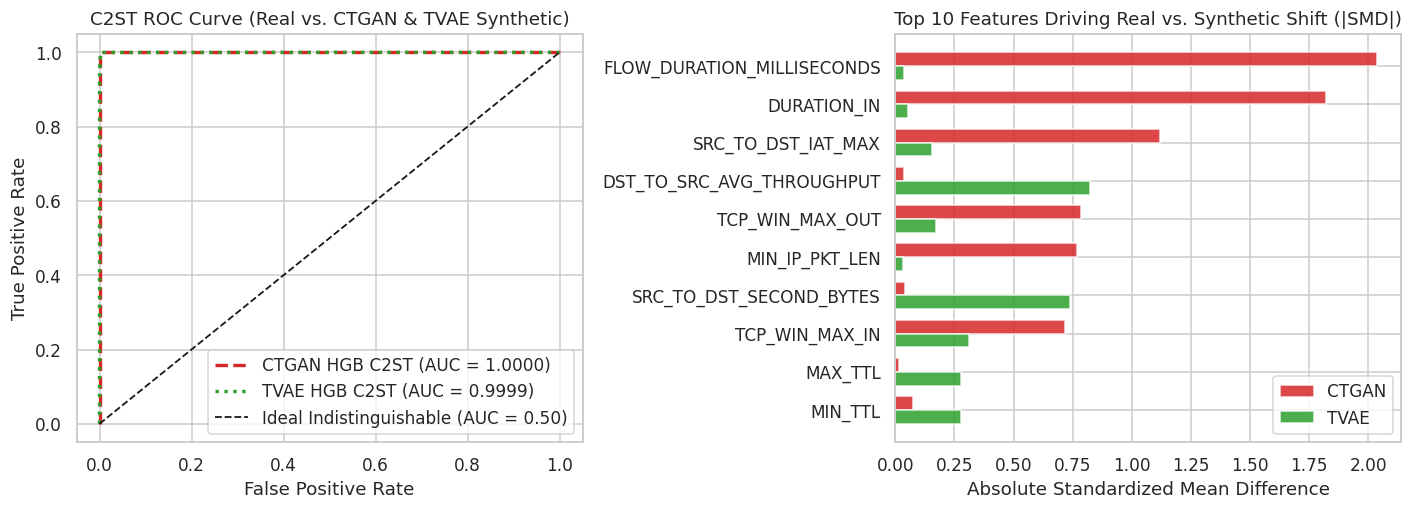

CTGAN C2ST 5-Fold ROC-AUC: 1.0000 (Target: ~0.50; >0.80 indicates clear distinguishability)
TVAE C2ST 5-Fold ROC-AUC: 0.9999 (Target: ~0.50; >0.80 indicates clear distinguishability)


In [3]:
# Metric 1: Classifier Two-Sample Test (C2ST) for CTGAN & TVAE
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
c2st_results = {}
smd_dict = {}

for name, syn_df in syn_datasets.items():
    cov_cls = sorted(syn_df["Attack"].unique())
    real_pool = real_attacks[real_attacks["Attack"].isin(cov_cls)]
    real_sample = real_pool.sample(n=min(len(real_pool), 4000), random_state=SEED)

    X_real_c2, med_c2 = clean_numeric(real_sample, feature_cols)
    X_syn_c2, _ = clean_numeric(syn_df, feature_cols, med_c2)
    X_c2 = pd.concat([X_real_c2, X_syn_c2], ignore_index=True)
    y_c2 = np.r_[np.zeros(len(X_real_c2), dtype=int), np.ones(len(X_syn_c2), dtype=int)]

    clf_hgb = HistGradientBoostingClassifier(max_depth=5, max_iter=100, random_state=SEED)
    probs_c2 = cross_val_predict(clf_hgb, X_c2, y_c2, cv=cv, method="predict_proba")[:, 1]
    auc = roc_auc_score(y_c2, probs_c2)
    fpr, tpr, _ = roc_curve(y_c2, probs_c2)
    c2st_results[name] = {"auc": auc, "fpr": fpr, "tpr": tpr}

    mu_r = X_real_c2[cont_cols].mean()
    sd_r = X_real_c2[cont_cols].std().replace(0, 1.0)
    smd_dict[name] = (X_syn_c2[cont_cols].mean() - mu_r).abs() / sd_r

smd_df = pd.DataFrame(smd_dict)
top10_feats = smd_df.max(axis=1).sort_values(ascending=False).head(10).index
smd_top10 = smd_df.loc[top10_feats].iloc[::-1]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for name, res in c2st_results.items():
    axes[0].plot(
        res["fpr"], res["tpr"],
        color=SYN_COLORS[name], linestyle=SYN_LINESTYLES[name], lw=2.2,
        label=f"{name} HGB C2ST (AUC = {res['auc']:.4f})"
    )
axes[0].plot([0, 1], [0, 1], "k--", lw=1.2, label="Ideal Indistinguishable (AUC = 0.50)")
axes[0].set_title("C2ST ROC Curve (Real vs. CTGAN & TVAE Synthetic)")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend(loc="lower right")

y_pos = np.arange(len(smd_top10))
h = 0.36
axes[1].barh(y_pos + h/2, smd_top10["CTGAN"], height=h, color=SYN_COLORS["CTGAN"], alpha=0.85, label="CTGAN")
axes[1].barh(y_pos - h/2, smd_top10["TVAE"], height=h, color=SYN_COLORS["TVAE"], alpha=0.85, label="TVAE")
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(smd_top10.index)
axes[1].set_title("Top 10 Features Driving Real vs. Synthetic Shift (|SMD|)")
axes[1].set_xlabel("Absolute Standardized Mean Difference")
axes[1].legend()
plt.tight_layout()
plt.show()
for name, res in c2st_results.items():
    print(f"{name} C2ST 5-Fold ROC-AUC: {res['auc']:.4f} (Target: ~0.50; >0.80 indicates clear distinguishability)")

## 3. Statistical Reliability — Categorical TVD & Effective Sample Reliability Gate ($n_{\text{eff}} \ge 30$)
**Reference:** Benjamini & Hochberg (1995); Patki et al. (2016), *SDV* (`10.1109/DSAA.2016.49`); Wolf et al. (2026), CISIS 2026 (`10.1007/978-3-032-29251-3`).  
**Interpretation:** Left: Total Variation Distance (TVD) on discrete NetFlow protocol/flag columns (`TVD < 0.10` ideal). Right: Per-class synthetic sample counts vs. the minimum statistical reliability gate ($n_{\text{eff}} \ge 30$), flagging classes where correlation or tail estimates are underpowered.

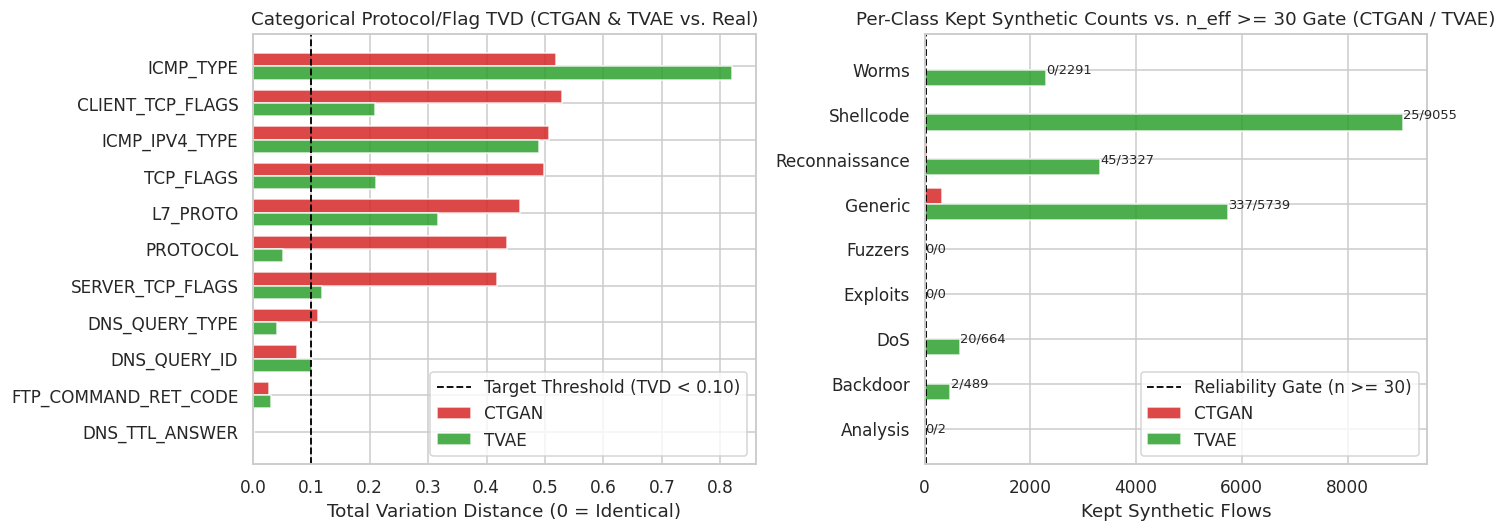

CTGAN -> Mean Categorical TVD: 0.3254 | Classes passing n_eff >= 30: 2/9
TVAE -> Mean Categorical TVD: 0.2172 | Classes passing n_eff >= 30: 6/9


In [4]:
# Metric 3: Categorical TVD + Effective Sample Gate (n_eff >= 30) for CTGAN & TVAE
tvd_dict = {}
syn_counts_dict = {}
all_attack_classes = sorted(real_attacks["Attack"].unique())

for name, syn_df in syn_datasets.items():
    cov_cls = sorted(syn_df["Attack"].unique())
    real_cat_pool = real_attacks[real_attacks["Attack"].isin(cov_cls)]
    tvd_map = {}
    for col in cat_cols:
        p_r = real_cat_pool[col].astype(str).value_counts(normalize=True)
        p_s = syn_df[col].astype(str).value_counts(normalize=True)
        cats = p_r.index.union(p_s.index)
        p_r_al = p_r.reindex(cats, fill_value=0.0)
        p_s_al = p_s.reindex(cats, fill_value=0.0)
        tvd_map[col] = 0.5 * float((p_r_al - p_s_al).abs().sum())
    tvd_dict[name] = pd.Series(tvd_map)
    syn_counts_dict[name] = syn_df["Attack"].value_counts().reindex(all_attack_classes, fill_value=0)

tvd_cmp = pd.DataFrame(tvd_dict)
tvd_cmp = tvd_cmp.loc[tvd_cmp.max(axis=1).sort_values(ascending=True).index]
counts_cmp = pd.DataFrame(syn_counts_dict)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5))
y_t = np.arange(len(tvd_cmp))
h = 0.36
axes[0].barh(y_t + h/2, tvd_cmp["CTGAN"], height=h, color=SYN_COLORS["CTGAN"], alpha=0.85, label="CTGAN")
axes[0].barh(y_t - h/2, tvd_cmp["TVAE"], height=h, color=SYN_COLORS["TVAE"], alpha=0.85, label="TVAE")
axes[0].axvline(0.10, color="black", linestyle="--", lw=1.2, label="Target Threshold (TVD < 0.10)")
axes[0].set_yticks(y_t)
axes[0].set_yticklabels(tvd_cmp.index)
axes[0].set_title("Categorical Protocol/Flag TVD (CTGAN & TVAE vs. Real)")
axes[0].set_xlabel("Total Variation Distance (0 = Identical)")
axes[0].legend()

y_c = np.arange(len(counts_cmp))
axes[1].barh(y_c + h/2, counts_cmp["CTGAN"], height=h, color=SYN_COLORS["CTGAN"], alpha=0.85, label="CTGAN")
axes[1].barh(y_c - h/2, counts_cmp["TVAE"], height=h, color=SYN_COLORS["TVAE"], alpha=0.85, label="TVAE")
axes[1].axvline(30, color="black", linestyle="--", lw=1.2, label="Reliability Gate (n >= 30)")
for i, (vc, vt) in enumerate(zip(counts_cmp["CTGAN"], counts_cmp["TVAE"])):
    axes[1].text(max(vc, vt) + 4, i, f"{vc}/{vt}", va="center", fontsize=8.5)
axes[1].set_yticks(y_c)
axes[1].set_yticklabels(counts_cmp.index)
axes[1].set_title("Per-Class Kept Synthetic Counts vs. n_eff >= 30 Gate (CTGAN / TVAE)")
axes[1].set_xlabel("Kept Synthetic Flows")
axes[1].legend()
plt.tight_layout()
plt.show()
for name in syn_datasets:
    print(f"{name} -> Mean Categorical TVD: {tvd_cmp[name].mean():.4f} | Classes passing n_eff >= 30: {(counts_cmp[name] >= 30).sum()}/{len(all_attack_classes)}")

## 4. Distribution Fidelity — Pure Synthetic KS Statistic & Normalized Wasserstein Distance
**Reference:** Xu et al. (2019), *CTGAN*, NeurIPS 2019 (`10.48550/arXiv.1907.00503`); Qian et al. (2023), *Synthcity* (`10.48550/arXiv.2301.07573`).  
**Interpretation:** Evaluates marginal fidelity **directly on pure synthetic flows** (`ctgan_syn` vs. `real_attacks`, avoiding dilution from the 690,228 real rows). Plots the top divergent continuous features by KS statistic and Normalized Wasserstein Distance, alongside the ECDF of the most divergent feature.

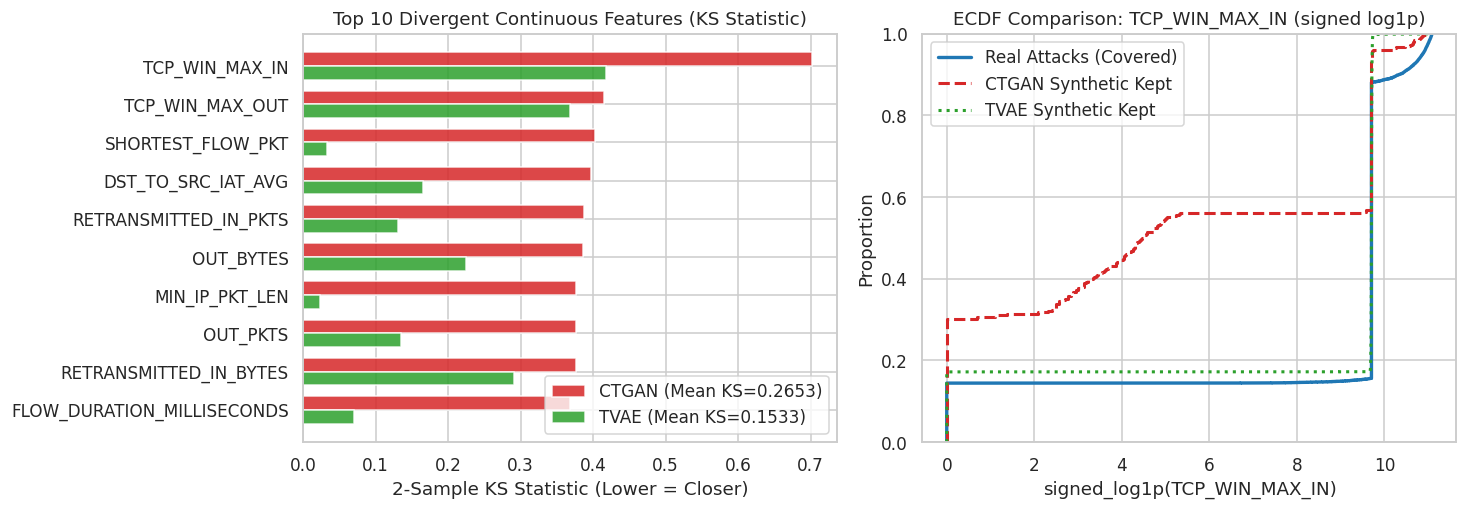

CTGAN -> Mean KS: 0.2653 | Mean Normalized Wasserstein: 0.02187
TVAE -> Mean KS: 0.1533 | Mean Normalized Wasserstein: 0.01818


In [5]:
# Metric 4: Pure Synthetic KS & Normalized Wasserstein Distance (CTGAN & TVAE)
fid_ks = {}
fid_wn = {}
real_fid_map = {}
syn_fid_map = {}

for name, syn_df in syn_datasets.items():
    cov_cls = sorted(syn_df["Attack"].unique())
    r_fid, med_fid = clean_numeric(real_attacks[real_attacks["Attack"].isin(cov_cls)], cont_cols)
    s_fid, _ = clean_numeric(syn_df, cont_cols, med_fid)
    real_fid_map[name] = r_fid
    syn_fid_map[name] = s_fid

    ks_map, wn_map = {}, {}
    for col in cont_cols:
        vr, vs = r_fid[col].values, s_fid[col].values
        ks_map[col] = float(ks_2samp(vr, vs).statistic)
        rng_val = max(1e-6, float(np.ptp(vr)))
        wn_map[col] = float(wasserstein_distance(vr, vs) / rng_val)
    fid_ks[name] = pd.Series(ks_map)
    fid_wn[name] = pd.Series(wn_map)

ks_cmp = pd.DataFrame(fid_ks)
wn_cmp = pd.DataFrame(fid_wn)
top10_ks = ks_cmp.loc[ks_cmp.max(axis=1).sort_values(ascending=False).head(10).index].iloc[::-1]
worst_feat = top10_ks.index[-1]

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
y_k = np.arange(len(top10_ks))
h = 0.36
axes[0].barh(y_k + h/2, top10_ks["CTGAN"], height=h, color=SYN_COLORS["CTGAN"], alpha=0.85, label=f"CTGAN (Mean KS={ks_cmp['CTGAN'].mean():.4f})")
axes[0].barh(y_k - h/2, top10_ks["TVAE"], height=h, color=SYN_COLORS["TVAE"], alpha=0.85, label=f"TVAE (Mean KS={ks_cmp['TVAE'].mean():.4f})")
axes[0].set_yticks(y_k)
axes[0].set_yticklabels(top10_ks.index)
axes[0].set_title("Top 10 Divergent Continuous Features (KS Statistic)")
axes[0].set_xlabel("2-Sample KS Statistic (Lower = Closer)")
axes[0].legend()

# Plot ECDF for worst feature (signed log1p scale)
vr_ref = real_fid_map["CTGAN"][worst_feat]
vr_log = np.sign(vr_ref) * np.log1p(np.abs(vr_ref))
sns.ecdfplot(vr_log, ax=axes[1], color="#1f77b4", label="Real Attacks (Covered)", lw=2.2)
for name in syn_datasets:
    vs_ref = syn_fid_map[name][worst_feat]
    vs_log = np.sign(vs_ref) * np.log1p(np.abs(vs_ref))
    sns.ecdfplot(vs_log, ax=axes[1], color=SYN_COLORS[name], linestyle=SYN_LINESTYLES[name], label=f"{name} Synthetic Kept", lw=2.0)
axes[1].set_title(f"ECDF Comparison: {worst_feat} (signed log1p)")
axes[1].set_xlabel(f"signed_log1p({worst_feat})")
axes[1].legend()
plt.tight_layout()
plt.show()
for name in syn_datasets:
    print(f"{name} -> Mean KS: {ks_cmp[name].mean():.4f} | Mean Normalized Wasserstein: {wn_cmp[name].mean():.5f}")

## 5. Distribution Fidelity — Spearman Correlation Difference Norm ($\|C_{\text{real}} - C_{\text{syn}}\|_F$)
**Reference:** Xu et al. (2019), *CTGAN*, NeurIPS 2019 (`10.48550/arXiv.1907.00503`); Qian et al. (2023), *Synthcity*.  
**Interpretation:** Compares the pairwise Spearman rank-correlation structure across continuous NetFlow attributes between `real_attacks` and `ctgan_syn` via the Frobenius norm and Mean Absolute Correlation Error (MACE).

CTGAN -> MACE (15 features): 0.2681 | Frobenius Norm: 5.3513


TVAE -> MACE (15 features): 0.1320 | Frobenius Norm: 2.5420


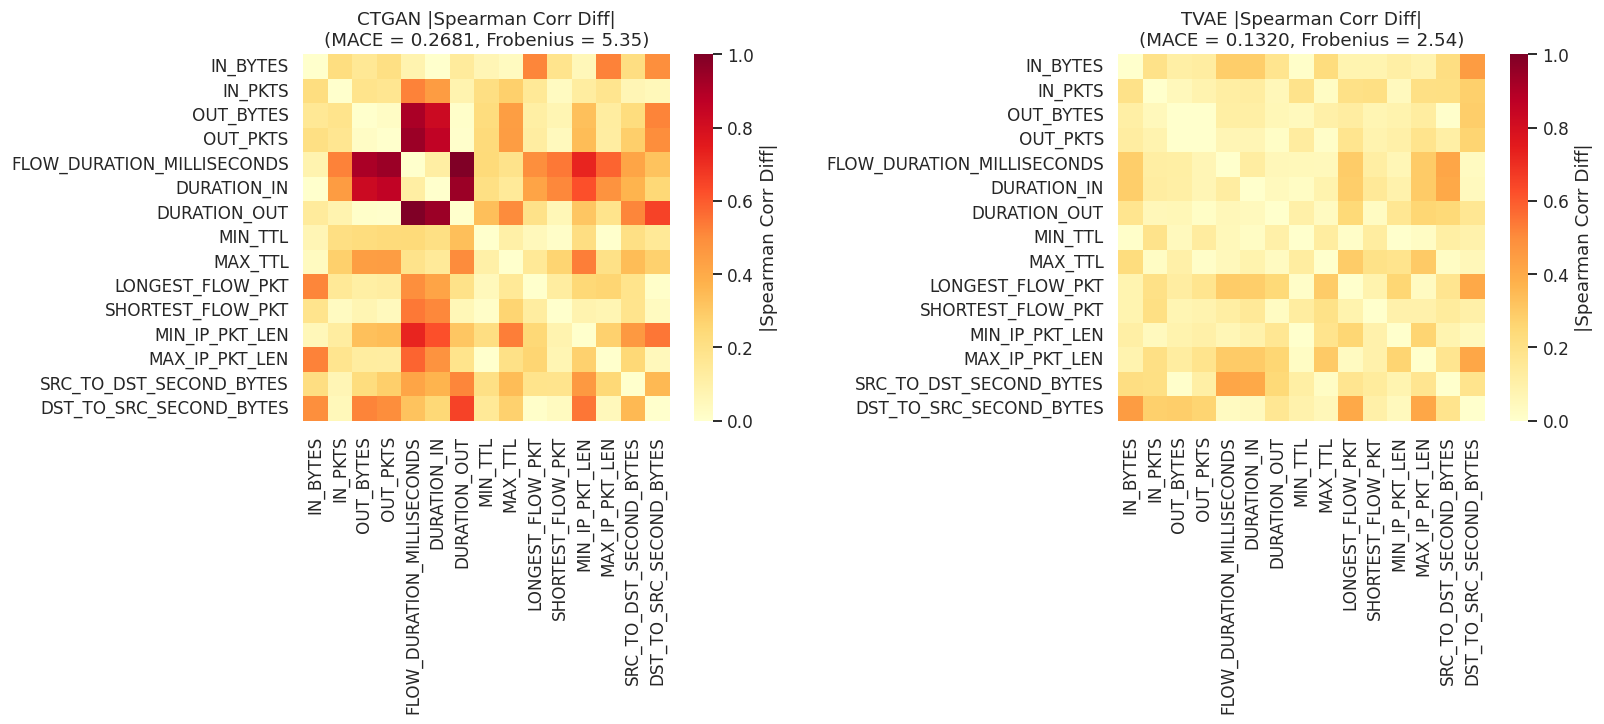

In [6]:
# Metric 5: Spearman Correlation Difference Norm (CTGAN & TVAE)
nonconst_cols = [
    c for c in cont_cols
    if real_fid_map["CTGAN"][c].std() > 0
    and all(syn_fid_map[name][c].std() > 0 for name in syn_datasets)
][:15]

fig, axes = plt.subplots(1, 2, figsize=(15, 6.2))
for ax, (name, syn_df) in zip(axes, syn_datasets.items()):
    corr_real = real_fid_map[name][nonconst_cols].corr(method="spearman").fillna(0.0)
    corr_syn = syn_fid_map[name][nonconst_cols].corr(method="spearman").fillna(0.0)
    corr_diff = (corr_real - corr_syn).abs()
    frob_norm = float(np.linalg.norm((corr_real - corr_syn).values, ord="fro"))
    mace = float(corr_diff.values.mean())

    sns.heatmap(corr_diff, cmap="YlOrRd", vmin=0.0, vmax=1.0, square=True, ax=ax, cbar_kws={"label": "|Spearman Corr Diff|"})
    ax.set_title(f"{name} |Spearman Corr Diff|\n(MACE = {mace:.4f}, Frobenius = {frob_norm:.2f})")
    print(f"{name} -> MACE (15 features): {mace:.4f} | Frobenius Norm: {frob_norm:.4f}")

plt.tight_layout()
plt.show()

## 6. Distribution Fidelity & Coverage — Generative Precision & Recall ($k$-NN Manifold Support)
**Reference:** Sajjadi et al. (2018), *Assessing Generative Models via Precision and Recall*, NeurIPS 2018 (`10.48550/arXiv.1806.00035`); Alaa et al. (2022), *How Faithful is your Synthetic Data?*, ICML 2022 (`10.48550/arXiv.2102.08921`).  
**Interpretation:** Estimates real vs. synthetic manifold support using $k$-NN hypersphere radii ($k=5$) in standardized `signed_log1p` space: **Precision** = fraction of synthetic rows inside real support (realism); **Recall** = fraction of real rows inside synthetic support (diversity/mode coverage).

CTGAN -> Generative Precision: 0.2191 | Generative Recall: 0.4820


TVAE -> Generative Precision: 0.5297 | Generative Recall: 0.4960


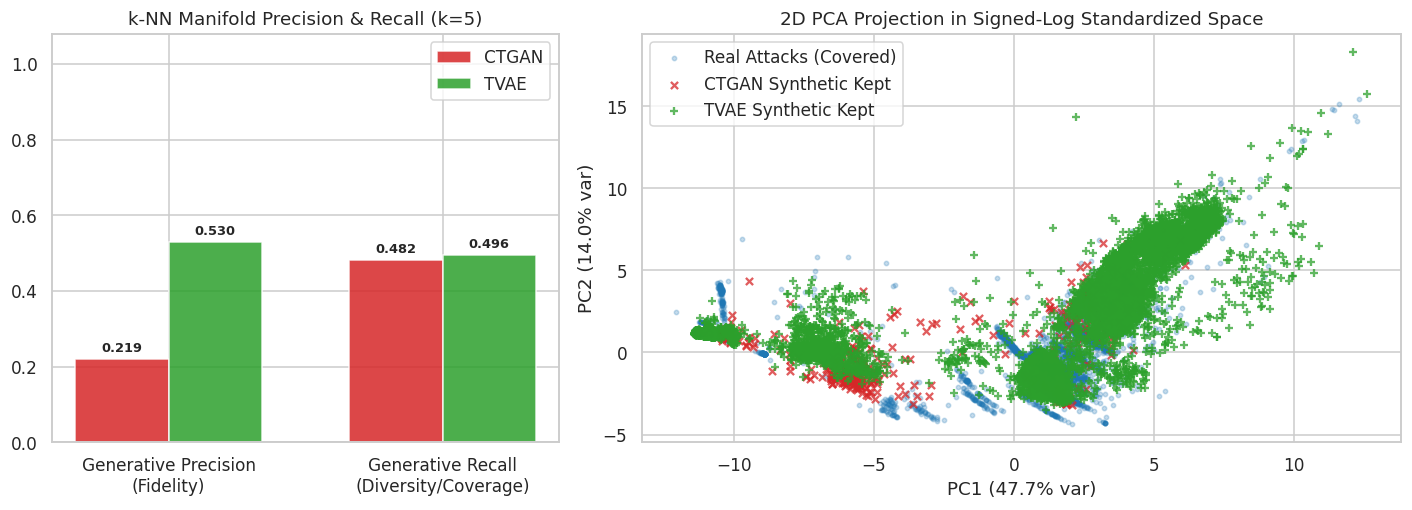

In [7]:
# Metric 6: Generative Precision & Recall (k-NN Manifold Support, k=5) for CTGAN & TVAE
def signed_log(X):
    return np.sign(X) * np.log1p(np.abs(X))

cov_all = sorted(set(ctgan_syn["Attack"].unique()) | set(tvae_syn["Attack"].unique()))
real_m_pool = real_attacks[real_attacks["Attack"].isin(cov_all)].sample(n=4000, random_state=SEED)
Xr_raw, med_m = clean_numeric(real_m_pool, feature_cols)
scaler_m = StandardScaler().fit(signed_log(Xr_raw.values))
Er = scaler_m.transform(signed_log(Xr_raw.values))

k_nn = 5
nn_r = NearestNeighbors(n_neighbors=k_nn + 1).fit(Er)
rad_r = nn_r.kneighbors(Er)[0][:, k_nn]
nn_r1 = NearestNeighbors(n_neighbors=1).fit(Er)

pca = PCA(n_components=2, random_state=SEED)
Zr = pca.fit_transform(Er)

pr_rows = []
Zs_map = {}
for name, syn_df in syn_datasets.items():
    Xs_raw, _ = clean_numeric(syn_df, feature_cols, med_m)
    Es = scaler_m.transform(signed_log(Xs_raw.values))

    dist_s_to_r, idx_s_to_r = nn_r1.kneighbors(Es)
    gen_precision = float((dist_s_to_r[:, 0] <= rad_r[idx_s_to_r[:, 0]]).mean())

    nn_s = NearestNeighbors(n_neighbors=k_nn + 1).fit(Es)
    rad_s = nn_s.kneighbors(Es)[0][:, k_nn]
    dist_r_to_s, idx_r_to_s = NearestNeighbors(n_neighbors=1).fit(Es).kneighbors(Er)
    gen_recall = float((dist_r_to_s[:, 0] <= rad_s[idx_r_to_s[:, 0]]).mean())

    pr_rows.append({"Model": name, "Precision": gen_precision, "Recall": gen_recall})
    Zs_map[name] = pca.transform(Es)
    print(f"{name} -> Generative Precision: {gen_precision:.4f} | Generative Recall: {gen_recall:.4f}")

pr_df = pd.DataFrame(pr_rows).set_index("Model")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1, 1.5]})
x_pr = np.arange(2)
w = 0.34
axes[0].bar(x_pr - w/2, [pr_df.loc["CTGAN", "Precision"], pr_df.loc["CTGAN", "Recall"]], w, color=SYN_COLORS["CTGAN"], alpha=0.85, label="CTGAN")
axes[0].bar(x_pr + w/2, [pr_df.loc["TVAE", "Precision"], pr_df.loc["TVAE", "Recall"]], w, color=SYN_COLORS["TVAE"], alpha=0.85, label="TVAE")
axes[0].set_xticks(x_pr)
axes[0].set_xticklabels(["Generative Precision\n(Fidelity)", "Generative Recall\n(Diversity/Coverage)"])
axes[0].set_ylim(0, 1.08)
axes[0].set_title("k-NN Manifold Precision & Recall (k=5)")
for i, metric in enumerate(["Precision", "Recall"]):
    axes[0].text(i - w/2, pr_df.loc["CTGAN", metric] + 0.02, f"{pr_df.loc['CTGAN', metric]:.3f}", ha="center", fontsize=8.5, fontweight="bold")
    axes[0].text(i + w/2, pr_df.loc["TVAE", metric] + 0.02, f"{pr_df.loc['TVAE', metric]:.3f}", ha="center", fontsize=8.5, fontweight="bold")
axes[0].legend()

axes[1].scatter(Zr[:, 0], Zr[:, 1], s=8, alpha=0.25, color="#1f77b4", label="Real Attacks (Covered)")
for name in syn_datasets:
    Zs = Zs_map[name]
    axes[1].scatter(Zs[:, 0], Zs[:, 1], s=22, alpha=0.75, color=SYN_COLORS[name], marker=SYN_MARKERS[name], label=f"{name} Synthetic Kept")
axes[1].set_title("2D PCA Projection in Signed-Log Standardized Space")
axes[1].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} var)")
axes[1].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} var)")
axes[1].legend()
plt.tight_layout()
plt.show()

## 7. Class Balance — Normalized Shannon Entropy ($H_{\text{norm}}$) & Deficit Fulfillment Ratio (DFR)
**Reference:** Shannon (1948), *A Mathematical Theory of Communication* (`10.1002/j.1538-7305.1948.tb01338.x`); Sarhan et al. (2020), *BDTA* (`10.1007/978-3-030-72802-1_9`).  
**Interpretation:** Left: Normalized multi-class Shannon entropy $H_{\text{norm}} \in [0, 1]$ across all 9 attack classes (`1.0` = perfectly uniform attack balance). Right: Per-class Deficit Fulfillment Ratio (`kept / target_deficit` from `dataset/synthetic_deficit.json`).

CTGAN -> Class Coverage: 5/9 attack classes | Overall DFR: 0.97%
TVAE -> Class Coverage: 7/9 attack classes | Overall DFR: 48.42%


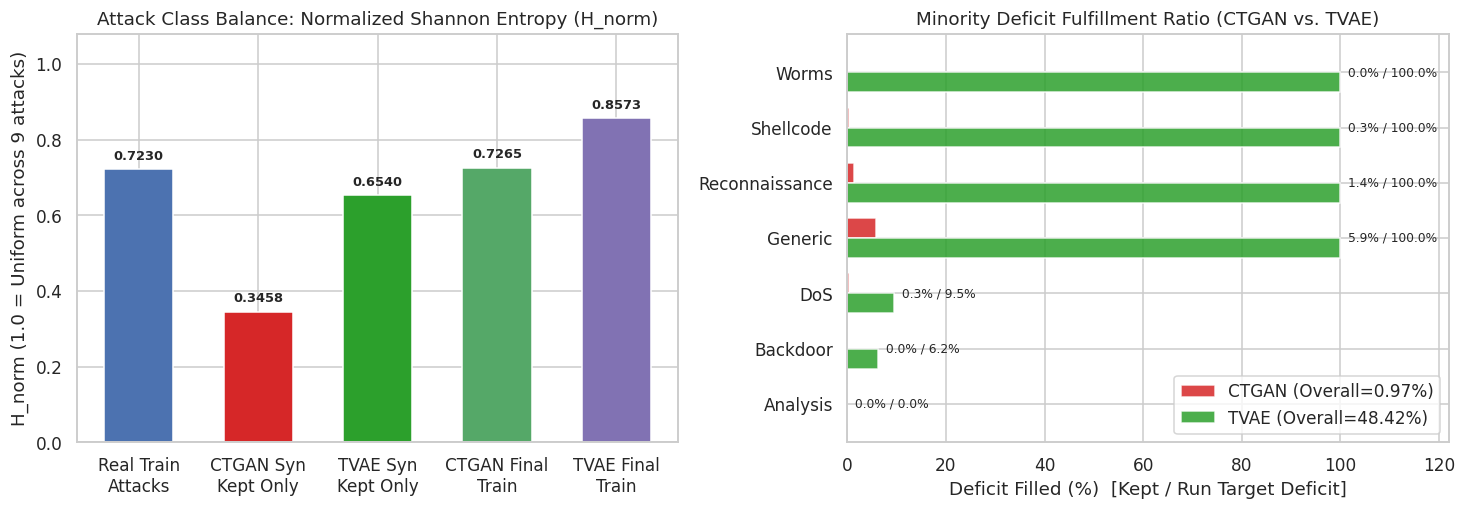

In [8]:
# Metric 7: Normalized Class Shannon Entropy & Deficit Fulfillment Ratio (DFR) for CTGAN & TVAE
def norm_shannon_entropy(series, classes):
    counts = series.value_counts().reindex(classes, fill_value=0).values.astype(float)
    total = counts.sum()
    if total == 0:
        return 0.0
    p = counts[counts > 0] / total
    return float(-np.sum(p * np.log(p)) / np.log(len(classes)))

atk_classes = sorted(deficit_cfg["synthetic_deficit"].keys())
h_real = norm_shannon_entropy(real_attacks["Attack"], atk_classes)
h_ctgan_syn = norm_shannon_entropy(ctgan_syn["Attack"], atk_classes)
h_tvae_syn = norm_shannon_entropy(tvae_syn["Attack"], atk_classes)
h_ctgan_final = norm_shannon_entropy(ctgan_final_train[ctgan_final_train["Label"] == 1]["Attack"], atk_classes)
h_tvae_final = norm_shannon_entropy(tvae_final_train[tvae_final_train["Label"] == 1]["Attack"], atk_classes)

deficits_map = {
    "CTGAN": pd.Series(ctgan_summary["best_parameters"]["round1_resampler_best_params"]["syn_deficit"]).reindex(atk_classes).fillna(0),
    "TVAE": pd.Series(tvae_summary["best_parameters"]["round1_resampler_best_params"]["syn_deficit"]).reindex(atk_classes).fillna(0),
}
dfr_dict = {}
overall_dfr_map = {}
for name, syn_df in syn_datasets.items():
    def_s = deficits_map[name]
    kept_cls = syn_df["Attack"].value_counts().reindex(atk_classes, fill_value=0)
    dfr_dict[name] = (kept_cls / def_s.replace(0, np.nan)).fillna(0.0)
    overall_dfr_map[name] = float(np.minimum(kept_cls, def_s).sum() / max(1, def_s.sum()))
    print(f"{name} -> Class Coverage: {(kept_cls > 0).sum()}/9 attack classes | Overall DFR: {overall_dfr_map[name]:.2%}")

any_def = (deficits_map["CTGAN"] > 0) | (deficits_map["TVAE"] > 0)
dfr_cmp = pd.DataFrame(dfr_dict)[any_def]
dfr_cmp = dfr_cmp.loc[dfr_cmp.max(axis=1).sort_values().index]

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
labels_h = ["Real Train\nAttacks", "CTGAN Syn\nKept Only", "TVAE Syn\nKept Only", "CTGAN Final\nTrain", "TVAE Final\nTrain"]
vals_h = [h_real, h_ctgan_syn, h_tvae_syn, h_ctgan_final, h_tvae_final]
cols_h = ["#4c72b0", SYN_COLORS["CTGAN"], SYN_COLORS["TVAE"], "#55a868", "#8172b3"]
axes[0].bar(labels_h, vals_h, color=cols_h, width=0.58)
axes[0].set_ylim(0, 1.08)
axes[0].set_title("Attack Class Balance: Normalized Shannon Entropy (H_norm)")
axes[0].set_ylabel("H_norm (1.0 = Uniform across 9 attacks)")
for i, v in enumerate(vals_h):
    axes[0].text(i, v + 0.025, f"{v:.4f}", ha="center", fontsize=8.5, fontweight="bold")

y_d = np.arange(len(dfr_cmp))
h = 0.36
axes[1].barh(y_d + h/2, dfr_cmp["CTGAN"] * 100, height=h, color=SYN_COLORS["CTGAN"], alpha=0.85, label=f"CTGAN (Overall={overall_dfr_map['CTGAN']:.2%})")
axes[1].barh(y_d - h/2, dfr_cmp["TVAE"] * 100, height=h, color=SYN_COLORS["TVAE"], alpha=0.85, label=f"TVAE (Overall={overall_dfr_map['TVAE']:.2%})")
for i, (vc, vt) in enumerate(zip(dfr_cmp["CTGAN"], dfr_cmp["TVAE"])):
    axes[1].text(max(vc, vt) * 100 + 1.5, i, f"{vc:.1%} / {vt:.1%}", va="center", fontsize=8)
axes[1].set_yticks(y_d)
axes[1].set_yticklabels(dfr_cmp.index)
axes[1].set_title("Minority Deficit Fulfillment Ratio (CTGAN vs. TVAE)")
axes[1].set_xlabel("Deficit Filled (%)  [Kept / Run Target Deficit]")
axes[1].set_xlim(0, min(122.0, dfr_cmp.max().max() * 100 + 22.0))
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

## 8. Class Balance & Utility — TSTR, Augmentation Gain ($\Delta$ TR+S vs. TRTR) & Bootstrap 95% CI
**Reference:** Xu et al. (2019), *CTGAN*, NeurIPS 2019 (`10.48550/arXiv.1907.00503`); Efron (1979), *Bootstrap Methods* (`10.1214/aos/1176344552`); Wolf et al. (2026), CISIS 2026 (`10.1007/978-3-032-29251-3`).  
**Interpretation:** Trains `HistGradientBoostingClassifier` on Real Train (`TRTR`), Synthetic-Only (`TSTR`), and Real + CTGAN Synthetic (`TR+S`), evaluating Macro F1 and Rare-Attack F1 on `NF-UNSW-NB15-v3_test.csv` with 95% bootstrap confidence intervals ($B=200$ test resamples).

CTGAN -> ML Efficacy (TSTR/TRTR): 0.1325 | Aug Gain (TR+S - TRTR): Macro=+0.0102, Rare=+0.0354


TVAE -> ML Efficacy (TSTR/TRTR): 0.0740 | Aug Gain (TR+S - TRTR): Macro=+0.0424, Rare=+0.0750


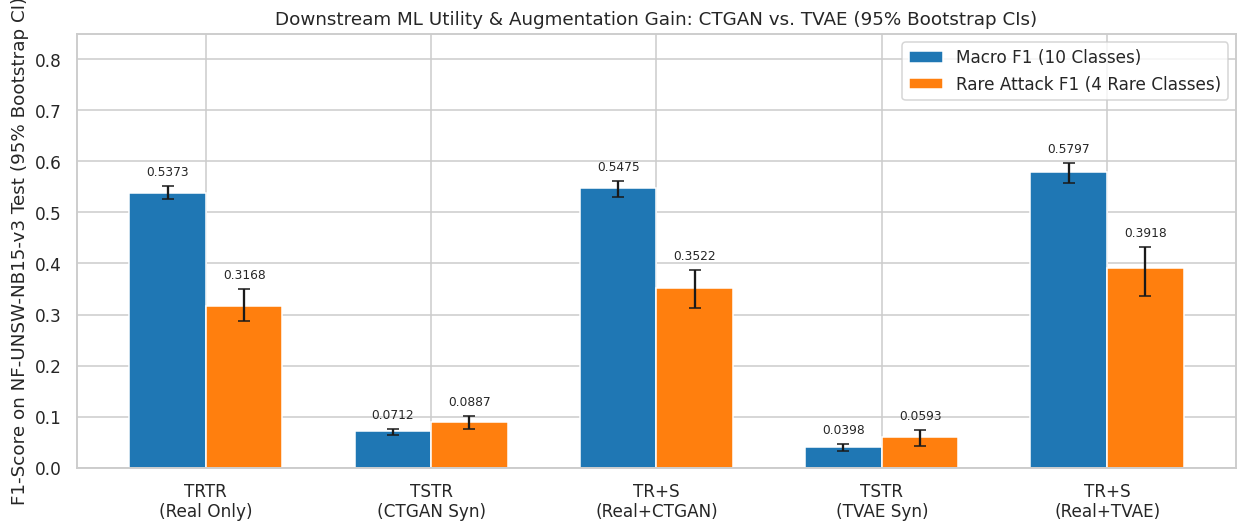

In [9]:
# Metric 8: TRTR vs TSTR vs TR+S with Bootstrap 95% CI (CTGAN & TVAE)
all_labels = sorted(train_df["Attack"].unique())
label_to_id = {l: i for i, l in enumerate(all_labels)}
rare_mask = np.isin(all_labels, RARE_CLASSES)

X_tr_u, med_u = clean_numeric(train_df, feature_cols)
y_tr_u = train_df["Attack"].map(label_to_id).values

X_te_u, _ = clean_numeric(test_df, feature_cols, med_u)
y_te_u = test_df["Attack"].map(label_to_id).values

def fit_eval_regime(X_train, y_train, name):
    sw = compute_sample_weight("balanced", y_train) ** 0.5
    clf = HistGradientBoostingClassifier(max_depth=8, max_iter=80, learning_rate=0.1, random_state=SEED)
    clf.fit(X_train, y_train, sample_weight=sw)
    preds = clf.predict(X_te_u)
    macro_b, rare_b = [], []
    n_te = len(y_te_u)
    for _ in range(200):
        idx = rng.integers(0, n_te, size=n_te)
        f1_c = f1_score(y_te_u[idx], preds[idx], labels=np.arange(len(all_labels)), average=None, zero_division=0)
        macro_b.append(f1_c.mean())
        rare_b.append(f1_c[rare_mask].mean())
    f1_full = f1_score(y_te_u, preds, labels=np.arange(len(all_labels)), average=None, zero_division=0)
    return {
        "regime": name,
        "macro_f1": float(f1_full.mean()),
        "macro_lo": float(np.percentile(macro_b, 2.5)),
        "macro_hi": float(np.percentile(macro_b, 97.5)),
        "rare_f1": float(f1_full[rare_mask].mean()),
        "rare_lo": float(np.percentile(rare_b, 2.5)),
        "rare_hi": float(np.percentile(rare_b, 97.5)),
    }

regimes = [fit_eval_regime(X_tr_u, y_tr_u, "TRTR\n(Real Only)")]
for name, syn_df in syn_datasets.items():
    X_syn_u, _ = clean_numeric(syn_df, feature_cols, med_u)
    y_syn_u = syn_df["Attack"].map(label_to_id).values
    res_tstr = fit_eval_regime(X_syn_u, y_syn_u, f"TSTR\n({name} Syn)")
    res_trs = fit_eval_regime(pd.concat([X_tr_u, X_syn_u], ignore_index=True), np.r_[y_tr_u, y_syn_u], f"TR+S\n(Real+{name})")
    regimes.extend([res_tstr, res_trs])
    print(f"{name} -> ML Efficacy (TSTR/TRTR): {res_tstr['macro_f1']/regimes[0]['macro_f1']:.4f} | Aug Gain (TR+S - TRTR): Macro={res_trs['macro_f1']-regimes[0]['macro_f1']:+.4f}, Rare={res_trs['rare_f1']-regimes[0]['rare_f1']:+.4f}")

util_df = pd.DataFrame(regimes)
fig, ax = plt.subplots(figsize=(11.5, 5.0))
x = np.arange(len(util_df))
w = 0.34
ax.bar(x - w/2, util_df["macro_f1"], w, yerr=[util_df["macro_f1"] - util_df["macro_lo"], util_df["macro_hi"] - util_df["macro_f1"]], capsize=4, label="Macro F1 (10 Classes)", color="#1f77b4")
ax.bar(x + w/2, util_df["rare_f1"], w, yerr=[util_df["rare_f1"] - util_df["rare_lo"], util_df["rare_hi"] - util_df["rare_f1"]], capsize=4, label="Rare Attack F1 (4 Rare Classes)", color="#ff7f0e")
ax.set_xticks(x)
ax.set_xticklabels(util_df["regime"])
ax.set_ylim(0, 0.85)
ax.set_ylabel("F1-Score on NF-UNSW-NB15-v3 Test (95% Bootstrap CI)")
ax.set_title("Downstream ML Utility & Augmentation Gain: CTGAN vs. TVAE (95% Bootstrap CIs)")
for i, row in util_df.iterrows():
    ax.text(i - w/2, row["macro_hi"] + 0.02, f"{row['macro_f1']:.4f}", ha="center", fontsize=8)
    ax.text(i + w/2, row["rare_hi"] + 0.02, f"{row['rare_f1']:.4f}", ha="center", fontsize=8)
ax.legend()
plt.tight_layout()
plt.show()

## 9. Security & Protocol Validity — NetFlow Cross-Feature Invariant Rate (PFIR) & Boundary Adherence
**Reference:** Ring et al. (2019), *Computers & Security* (`10.1016/j.cose.2018.12.012`); Yin et al. (2022), *NetShare*, ACM SIGCOMM (`10.1145/3544216.3544251`); Patki et al. (2016), *SDV* (`10.1109/DSAA.2016.49`).  
**Interpretation:** Audits `ctgan_syn` against concrete RFC/NetFlow cross-feature invariants (`MIN_TTL <= MAX_TTL`, `SHORTEST_FLOW_PKT <= LONGEST_FLOW_PKT <= MAX_IP_PKT_LEN`, `IN_BYTES >= IN_PKTS`, `TCP_FLAGS == 0` for UDP, `ICMP_TYPE == 0` for TCP/UDP, and `BoundaryAdherence` inside real `[min, max]`).

CTGAN -> Strict All-Invariants Pass Rate (PFIR): 8.39% (36/429 rows)


TVAE -> Strict All-Invariants Pass Rate (PFIR): 9.11% (1965/21567 rows)


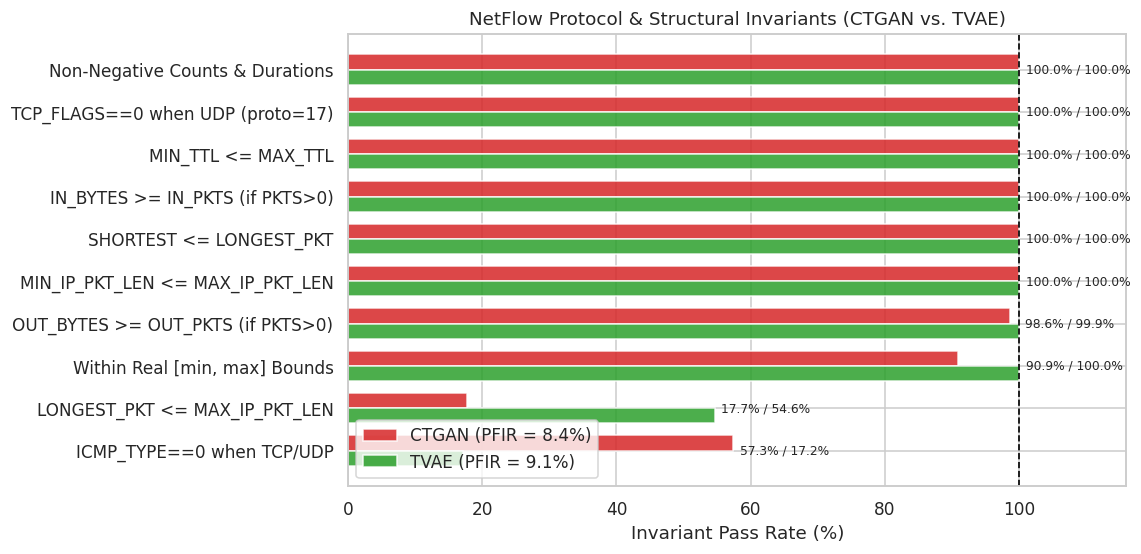

In [10]:
# Metric 9: NetFlow Protocol Invariant Rate (PFIR) & Boundary Adherence (CTGAN & TVAE)
r_num, _ = clean_numeric(real_attacks, feature_cols)
r_min, r_max = r_num.min(), r_num.max()

inv_dict = {}
pfir_map = {}
for name, syn_df in syn_datasets.items():
    s = syn_df.copy()
    s_num, _ = clean_numeric(s, feature_cols)
    invariants = {
        "MIN_TTL <= MAX_TTL": (s["MIN_TTL"] <= s["MAX_TTL"]),
        "SHORTEST <= LONGEST_PKT": (s["SHORTEST_FLOW_PKT"] <= s["LONGEST_FLOW_PKT"]),
        "LONGEST_PKT <= MAX_IP_PKT_LEN": (s["LONGEST_FLOW_PKT"] <= s["MAX_IP_PKT_LEN"]),
        "MIN_IP_PKT_LEN <= MAX_IP_PKT_LEN": (s["MIN_IP_PKT_LEN"] <= s["MAX_IP_PKT_LEN"]),
        "IN_BYTES >= IN_PKTS (if PKTS>0)": ((s["IN_PKTS"] == 0) | (s["IN_BYTES"] >= s["IN_PKTS"])),
        "OUT_BYTES >= OUT_PKTS (if PKTS>0)": ((s["OUT_PKTS"] == 0) | (s["OUT_BYTES"] >= s["OUT_PKTS"])),
        "TCP_FLAGS==0 when UDP (proto=17)": ((s["PROTOCOL"] != 17) | (s["TCP_FLAGS"] == 0)),
        "ICMP_TYPE==0 when TCP/UDP": ((~s["PROTOCOL"].isin([6, 17])) | (s["ICMP_TYPE"] == 0)),
        "Non-Negative Counts & Durations": ((s_num >= 0).all(axis=1)),
        "Within Real [min, max] Bounds": (((s_num >= r_min) & (s_num <= r_max)).all(axis=1)),
    }
    inv_dict[name] = {k: float(v.mean()) for k, v in invariants.items()}
    all_valid = np.ones(len(s), dtype=bool)
    for mask in invariants.values():
        all_valid &= mask.values
    pfir_map[name] = float(all_valid.mean())
    print(f"{name} -> Strict All-Invariants Pass Rate (PFIR): {pfir_map[name]:.2%} ({all_valid.sum()}/{len(s)} rows)")

inv_cmp = pd.DataFrame(inv_dict)
inv_cmp = inv_cmp.loc[inv_cmp.min(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(10.5, 5.2))
y_i = np.arange(len(inv_cmp))
h = 0.36
ax.barh(y_i + h/2, inv_cmp["CTGAN"] * 100, height=h, color=SYN_COLORS["CTGAN"], alpha=0.85, label=f"CTGAN (PFIR = {pfir_map['CTGAN']:.1%})")
ax.barh(y_i - h/2, inv_cmp["TVAE"] * 100, height=h, color=SYN_COLORS["TVAE"], alpha=0.85, label=f"TVAE (PFIR = {pfir_map['TVAE']:.1%})")
ax.axvline(100.0, color="black", linestyle="--", lw=1.1)
for i, (vc, vt) in enumerate(zip(inv_cmp["CTGAN"], inv_cmp["TVAE"])):
    ax.text(min(max(vc, vt) * 100 + 1.0, 101.5), i, f"{vc:.1%} / {vt:.1%}", va="center", fontsize=8)
ax.set_yticks(y_i)
ax.set_yticklabels(inv_cmp.index)
ax.set_xlim(0, 116)
ax.set_xlabel("Invariant Pass Rate (%)")
ax.set_title("NetFlow Protocol & Structural Invariants (CTGAN vs. TVAE)")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

## 10. NetFlow Security Structure — L2 Directional Asymmetry JSD & L3 TCP-Flag Entropy
**Reference:** Ring et al. (2019), *Computers & Security* (`10.1016/j.cose.2018.12.012`); Yin et al. (2022), *NetShare* (`10.1145/3544216.3544251`); Shannon (1948) (`10.1002/j.1538-7305.1948.tb01338.x`).  
**Interpretation:** Left: L2 directional asymmetry ratio `IN_BYTES / (IN_BYTES + OUT_BYTES)` comparing unidirectional vs. bidirectional session structure via Jensen-Shannon Divergence (JSD). Right: L3 Shannon entropy across `TCP_FLAGS`, `CLIENT_TCP_FLAGS`, and `SERVER_TCP_FLAGS`.

CTGAN -> L2 Directional Asymmetry JSD: 0.1501 | L3 Mean Flag Entropy Diff: 0.3469 bits
TVAE -> L2 Directional Asymmetry JSD: 0.1491 | L3 Mean Flag Entropy Diff: 0.7424 bits


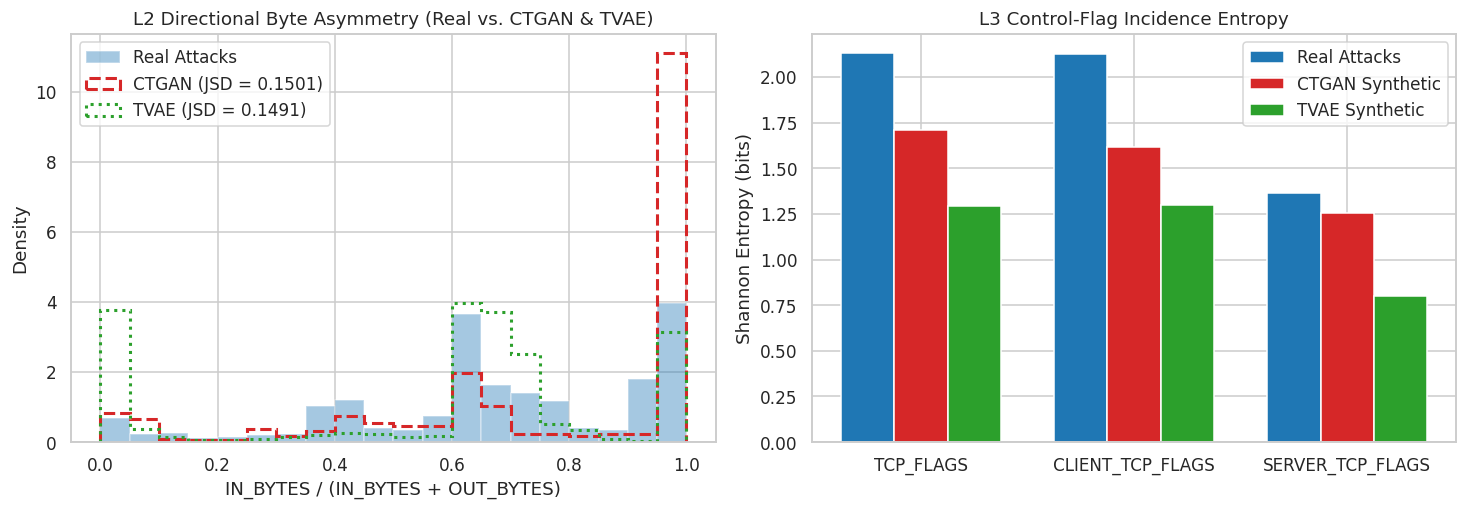

In [11]:
# Metric 10: L2 Directional Asymmetry JSD & L3 TCP-Flag Entropy (CTGAN & TVAE)
real_l = real_attacks[real_attacks["Attack"].isin(cov_all)]
eps = 1e-9
asym_real = (real_l["IN_BYTES"] / (real_l["IN_BYTES"] + real_l["OUT_BYTES"] + eps)).clip(0, 1)
bins = np.linspace(0, 1, 21)
p_r, _ = np.histogram(asym_real, bins=bins, density=False)
p_r_norm = p_r / max(1, p_r.sum())

def shannon_entropy_bits(s):
    p = s.value_counts(normalize=True).values
    return float(-np.sum(p * np.log2(p + 1e-12)))

flag_cols = ["TCP_FLAGS", "CLIENT_TCP_FLAGS", "SERVER_TCP_FLAGS"]
ent_real = [shannon_entropy_bits(real_l[c]) for c in flag_cols]

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
axes[0].hist(asym_real, bins=bins, density=True, alpha=0.40, label="Real Attacks", color="#1f77b4")

ent_syn_map = {}
for name, syn_df in syn_datasets.items():
    asym_syn = (syn_df["IN_BYTES"] / (syn_df["IN_BYTES"] + syn_df["OUT_BYTES"] + eps)).clip(0, 1)
    p_s, _ = np.histogram(asym_syn, bins=bins, density=False)
    l2_jsd = float(jensenshannon(p_r_norm, p_s / max(1, p_s.sum()), base=2) ** 2)
    axes[0].hist(asym_syn, bins=bins, density=True, histtype="step", lw=2.0, linestyle=SYN_LINESTYLES[name], color=SYN_COLORS[name], label=f"{name} (JSD = {l2_jsd:.4f})")

    ent_syn = [shannon_entropy_bits(syn_df[c]) for c in flag_cols]
    ent_syn_map[name] = ent_syn
    print(f"{name} -> L2 Directional Asymmetry JSD: {l2_jsd:.4f} | L3 Mean Flag Entropy Diff: {np.mean(np.abs(np.array(ent_real)-np.array(ent_syn))):.4f} bits")

axes[0].set_title("L2 Directional Byte Asymmetry (Real vs. CTGAN & TVAE)")
axes[0].set_xlabel("IN_BYTES / (IN_BYTES + OUT_BYTES)")
axes[0].set_ylabel("Density")
axes[0].legend()

x_f = np.arange(len(flag_cols))
w = 0.25
axes[1].bar(x_f - w, ent_real, w, label="Real Attacks", color="#1f77b4")
axes[1].bar(x_f, ent_syn_map["CTGAN"], w, label="CTGAN Synthetic", color=SYN_COLORS["CTGAN"])
axes[1].bar(x_f + w, ent_syn_map["TVAE"], w, label="TVAE Synthetic", color=SYN_COLORS["TVAE"])
axes[1].set_xticks(x_f)
axes[1].set_xticklabels(flag_cols)
axes[1].set_ylabel("Shannon Entropy (bits)")
axes[1].set_title("L3 Control-Flag Incidence Entropy")
axes[1].legend()
plt.tight_layout()
plt.show()

## 11. Privacy & Novelty — Distance to Closest Record (DCR), Exact Copy & Mode-Collapse Rate
**Reference:** Qian et al. (2023), *Synthcity* (`10.48550/arXiv.2301.07573`); Alaa et al. (2022), *ICML* (`10.48550/arXiv.2102.08921`); Patki et al. (2016), *SDV* (`NewRowSynthesis`, `10.1109/DSAA.2016.49`).  
**Interpretation:** Computes 1-NN Euclidean distance in signed-log standardized space from `ctgan_syn` to `real_train` (`d_train`) vs. `holdout_df` (`d_holdout`), along with `NewRowSynthesis` (`1 - ExactCopyRate`) and `IntraSynDupRate` (duplicate rows within `ctgan_syn`).

CTGAN -> Exact Copy: 0.00% | NewRowSynthesis: 100.00% | Closer-to-Train: 58.74% | Intra-Syn Dup: 0.00%


TVAE -> Exact Copy: 0.00% | NewRowSynthesis: 100.00% | Closer-to-Train: 53.10% | Intra-Syn Dup: 0.00%


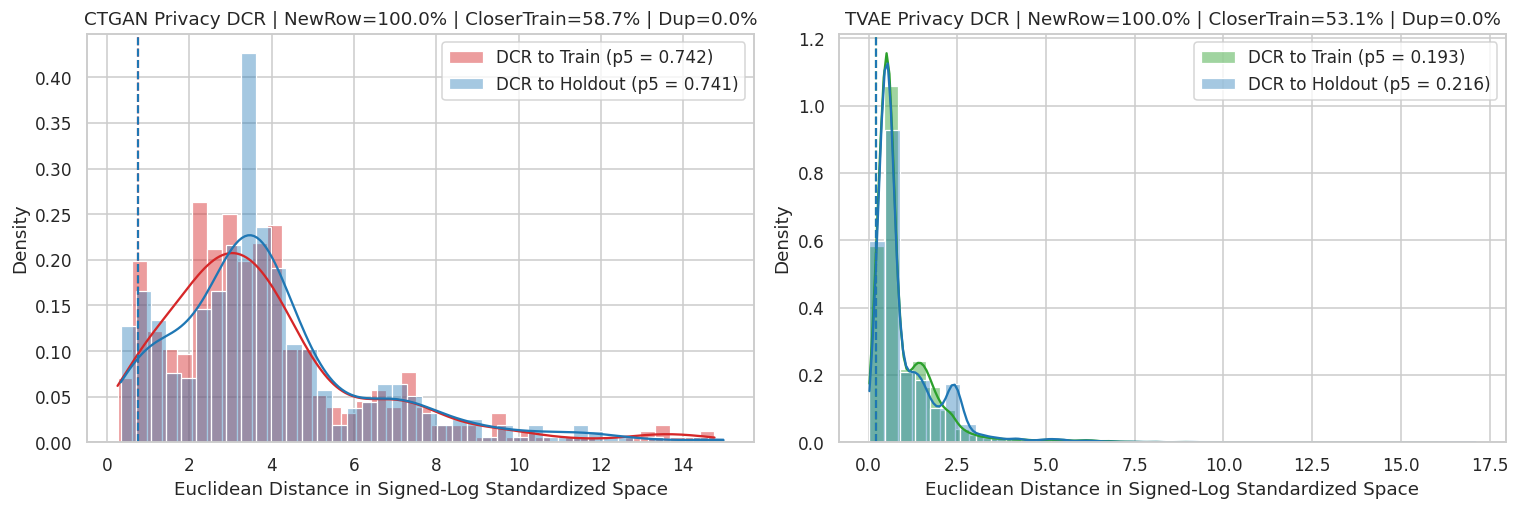

In [12]:
# Metric 11: DCR (Size-Matched Real Attacks vs Holdout Attacks), NewRowSynthesis, and Intra-Synthetic Duplication
n_ref = len(holdout_attacks)
tr_sub = real_attacks.sample(n=n_ref, random_state=SEED)
ho_sub = holdout_attacks.copy()

Xtr_p, med_p = clean_numeric(tr_sub, feature_cols)
Xho_p, _ = clean_numeric(ho_sub, feature_cols, med_p)

sc_p = StandardScaler().fit(signed_log(Xtr_p.values))
E_tr = sc_p.transform(signed_log(Xtr_p.values))
E_ho = sc_p.transform(signed_log(Xho_p.values))
nn_tr_p = NearestNeighbors(n_neighbors=1).fit(E_tr)
nn_ho_p = NearestNeighbors(n_neighbors=1).fit(E_ho)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, (name, syn_df) in zip(axes, syn_datasets.items()):
    Xsy_p, _ = clean_numeric(syn_df, feature_cols, med_p)
    E_sy = sc_p.transform(signed_log(Xsy_p.values))

    d_tr = nn_tr_p.kneighbors(E_sy)[0][:, 0]
    d_ho = nn_ho_p.kneighbors(E_sy)[0][:, 0]

    exact_copy_rate = float((d_tr < 1e-9).mean())
    new_row_synthesis = 1.0 - exact_copy_rate
    closer_to_train = float((d_tr < d_ho).mean())
    intra_dup_rate = float(syn_df.duplicated(subset=feature_cols).mean())

    sns.histplot(d_tr, bins=40, kde=True, stat="density", alpha=0.45, color=SYN_COLORS[name], label=f"DCR to Train (p5 = {np.percentile(d_tr, 5):.3f})", ax=ax)
    sns.histplot(d_ho, bins=40, kde=True, stat="density", alpha=0.40, color="#1f77b4", label=f"DCR to Holdout (p5 = {np.percentile(d_ho, 5):.3f})", ax=ax)
    ax.axvline(np.percentile(d_tr, 5), color=SYN_COLORS[name], linestyle="--", lw=1.4)
    ax.axvline(np.percentile(d_ho, 5), color="#1f77b4", linestyle="--", lw=1.4)
    ax.set_title(f"{name} Privacy DCR | NewRow={new_row_synthesis:.1%} | CloserTrain={closer_to_train:.1%} | Dup={intra_dup_rate:.1%}")
    ax.set_xlabel("Euclidean Distance in Signed-Log Standardized Space")
    ax.legend()
    print(f"{name} -> Exact Copy: {exact_copy_rate:.2%} | NewRowSynthesis: {new_row_synthesis:.2%} | Closer-to-Train: {closer_to_train:.2%} | Intra-Syn Dup: {intra_dup_rate:.2%}")

plt.tight_layout()
plt.show()

## 12. Downstream Two-Tier IDS Security & Balance — CTGAN (`result_2`) vs. TVAE (`result_2`)
**Reference:** Sarhan et al. (2020), *BDTA* (`10.1007/978-3-030-72802-1_9`); Chicco & Jurman (2020), *BMC Genomics* (`10.1186/s12864-019-6413-7`).  
**Interpretation:** Compares end-to-end Two-Tier IDS metrics across **Validation, Test, and Holdout** splits, plus **per-class Holdout F1, Precision, and Recall** across all 10 classes (highlighting the 4 rare classes).

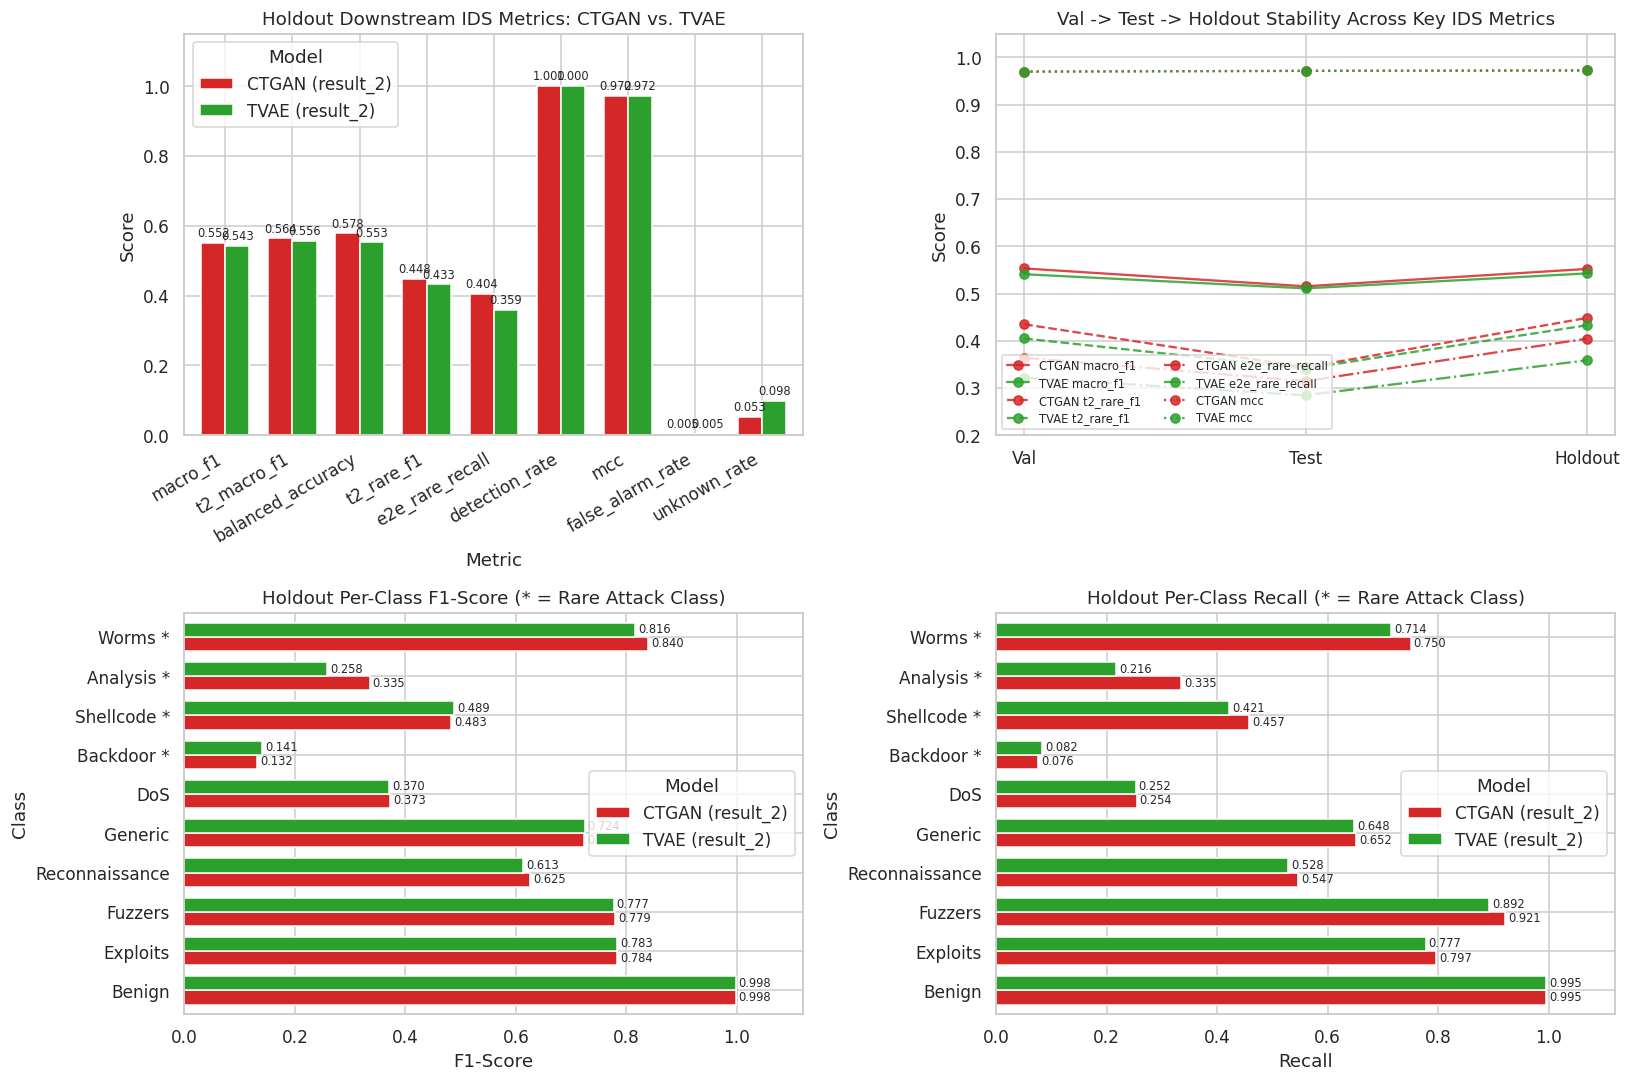

Model,CTGAN (result_2),TVAE (result_2)
Metric,,
macro_f1,0.5520,0.5426
t2_macro_f1,0.5643,0.5561
balanced_accuracy,0.5783,0.5528
t2_rare_f1,0.4483,0.4327
e2e_rare_recall,0.4044,0.3586
detection_rate,1.0000,1.0000
mcc,0.9723,0.9723
false_alarm_rate,0.0046,0.0046
unknown_rate,0.0527,0.0983


precision                           recall  \
Model          CTGAN (result_2) TVAE (result_2) CTGAN (result_2)   
Class                                                              
Benign                   1.0000          1.0000           0.9954   
Exploits                 0.7712          0.7895           0.7967   
Fuzzers                  0.6753          0.6877           0.9213   
Reconnaissance           0.7300          0.7293           0.5468   
Generic                  0.8124          0.8204           0.6518   
DoS                      0.7000          0.6949           0.2540   
Backdoor *               0.5043          0.4776           0.0759   
Shellcode *              0.5116          0.5820           0.4570   
Analysis *               0.3361          0.3193           0.3347   
Worms *                  0.9545          0.9524           0.7500   

                                             f1                  
Model          TVAE (result_2) CTGAN (result_2) TVAE (result_2)  
Class                                                            
Benign                  0.9954           0.9977          0.9977  
Exploits                0.7771           0.7837          0.7832  
Fuzzers                 0.8925           0.7793          0.7769  
Reconnaissance          0.5279           0.6252          0.6125  
Generic                 0.6485           0.7233          0.7244  
DoS                     0.2521           0.3727          0.3700  
Backdoor *              0.0824           0.1320          0.1405  
Shellcode *             0.4214           0.4828          0.4888  
Analysis *              0.2163           0.3354          0.2579  
Worms *                 0.7143           0.8400          0.8163

In [13]:
# Metric 12: Downstream IDS Multi-Split & Per-Class Holdout Breakdown (CTGAN result_2 vs TVAE result_2)
metrics_keys = ["macro_f1", "t2_macro_f1", "balanced_accuracy", "t2_rare_f1", "e2e_rare_recall", "detection_rate", "mcc", "false_alarm_rate", "unknown_rate"]
splits = [("validation_performance", "Val"), ("test_performance", "Test"), ("holdout_performance", "Holdout")]

rows_ids = []
for model_name, summ in [("CTGAN (result_2)", ctgan_summary), ("TVAE (result_2)", tvae_summary)]:
    for sp_key, sp_lbl in splits:
        sp = summ.get(sp_key, {})
        for mk in metrics_keys:
            rows_ids.append({"Model": model_name, "Split": sp_lbl, "Metric": mk, "Value": sp.get(mk, np.nan)})

ids_df = pd.DataFrame(rows_ids)
holdout_cmp = ids_df[ids_df["Split"] == "Holdout"].pivot(index="Metric", columns="Model", values="Value").loc[metrics_keys]

# Per-class Holdout metrics
pc_rows = []
for model_name, summ in [("CTGAN (result_2)", ctgan_summary), ("TVAE (result_2)", tvae_summary)]:
    pc = summ["holdout_performance"]["per_class"]
    for cls_name, vals in pc.items():
        pc_rows.append({
            "Model": model_name,
            "Class": f"{cls_name} *" if vals.get("is_rare") else cls_name,
            "raw_cls": cls_name,
            "is_rare": vals.get("is_rare", False),
            "precision": vals["precision"],
            "recall": vals["recall"],
            "f1": vals["f1"],
            "support": vals["support"],
        })
pc_df = pd.DataFrame(pc_rows)
cls_order = pc_df[pc_df["Model"] == "CTGAN (result_2)"].sort_values(["is_rare", "support"], ascending=[True, False])["Class"].tolist()

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Top-left: Holdout metrics bar chart
holdout_cmp.plot(kind="bar", ax=axes[0, 0], color=[SYN_COLORS["CTGAN"], SYN_COLORS["TVAE"]], width=0.72)
axes[0, 0].set_title("Holdout Downstream IDS Metrics: CTGAN vs. TVAE")
axes[0, 0].set_ylabel("Score")
axes[0, 0].set_ylim(0, 1.15)
axes[0, 0].set_xticklabels(axes[0, 0].get_xticklabels(), rotation=30, ha="right")
for container in axes[0, 0].containers:
    axes[0, 0].bar_label(container, fmt="%.3f", fontsize=7.5, padding=2)

# Top-right: Multi-split trajectory on key metrics
key_traj = ["macro_f1", "t2_rare_f1", "e2e_rare_recall", "mcc"]
split_order = ["Val", "Test", "Holdout"]
x_s = np.arange(len(split_order))
for mk, ls in zip(key_traj, ["-", "--", "-.", ":"]):
    for m_lbl, col in [("CTGAN (result_2)", SYN_COLORS["CTGAN"]), ("TVAE (result_2)", SYN_COLORS["TVAE"])]:
        sub = ids_df[(ids_df["Model"] == m_lbl) & (ids_df["Metric"] == mk)].set_index("Split").reindex(split_order)
        axes[0, 1].plot(x_s, sub["Value"], marker="o", linestyle=ls, color=col, alpha=0.85, label=f"{m_lbl.split()[0]} {mk}")
axes[0, 1].set_xticks(x_s)
axes[0, 1].set_xticklabels(split_order)
axes[0, 1].set_ylim(0.2, 1.05)
axes[0, 1].set_title("Val -> Test -> Holdout Stability Across Key IDS Metrics")
axes[0, 1].set_ylabel("Score")
axes[0, 1].legend(ncol=2, fontsize=7.5, loc="lower left")

# Bottom-left: Per-Class Holdout F1
f1_piv = pc_df.pivot(index="Class", columns="Model", values="f1").loc[cls_order]
f1_piv.plot(kind="barh", ax=axes[1, 0], color=[SYN_COLORS["CTGAN"], SYN_COLORS["TVAE"]], width=0.72)
axes[1, 0].set_title("Holdout Per-Class F1-Score (* = Rare Attack Class)")
axes[1, 0].set_xlabel("F1-Score")
axes[1, 0].set_xlim(0, 1.12)
for container in axes[1, 0].containers:
    axes[1, 0].bar_label(container, fmt="%.3f", fontsize=7.5, padding=2)

# Bottom-right: Per-Class Holdout Recall
rec_piv = pc_df.pivot(index="Class", columns="Model", values="recall").loc[cls_order]
rec_piv.plot(kind="barh", ax=axes[1, 1], color=[SYN_COLORS["CTGAN"], SYN_COLORS["TVAE"]], width=0.72)
axes[1, 1].set_title("Holdout Per-Class Recall (* = Rare Attack Class)")
axes[1, 1].set_xlabel("Recall")
axes[1, 1].set_xlim(0, 1.12)
for container in axes[1, 1].containers:
    axes[1, 1].bar_label(container, fmt="%.3f", fontsize=7.5, padding=2)

plt.tight_layout()
plt.show()
display(holdout_cmp.round(4))
display(pc_df.pivot(index="Class", columns="Model", values=["precision", "recall", "f1"]).loc[cls_order].round(4))

## 13. Pipeline Tuning Trajectories — Round 1 ($y_{\max}$) & Round 3 ($\theta_{\text{OOF}}$)
**Interpretation:** Compares how validation `macro_f1` and filtered synthetic sample yield evolved across Round 1 (`y_max` grid) and Round 3 (`oof_threshold` grid) for `CTGAN (result_2)` and `TVAE (result_2)`.

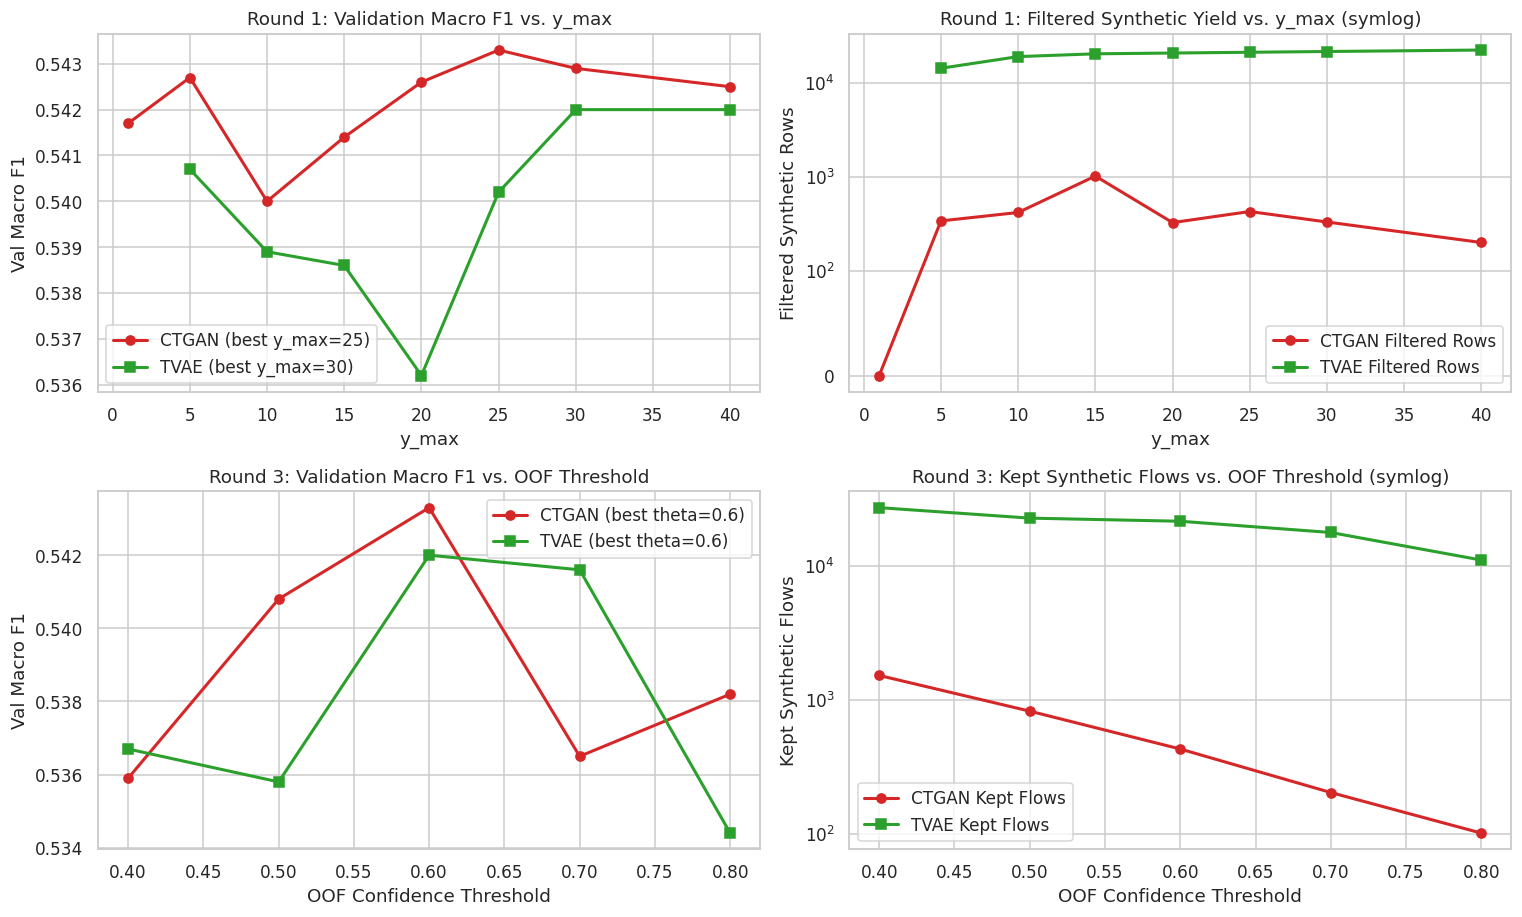

In [14]:
# Section 13: Round 1 (y_max) & Round 3 (OOF Threshold) Tuning Trajectories
r1_ctgan = pd.DataFrame(ctgan_summary["tuning_rounds_summary"]["round1"]["details"])
r1_tvae = pd.DataFrame(tvae_summary["tuning_rounds_summary"]["round1"]["details"])
r3_ctgan = pd.DataFrame(ctgan_summary["tuning_rounds_summary"]["round3"]["details"])
r3_tvae = pd.DataFrame(tvae_summary["tuning_rounds_summary"]["round3"]["details"])

fig, axes = plt.subplots(2, 2, figsize=(14, 8.5))

# R1 macro_f1
axes[0, 0].plot(r1_ctgan["y_max"], r1_ctgan["macro_f1"], marker="o", color=SYN_COLORS["CTGAN"], lw=2, label="CTGAN (best y_max=25)")
axes[0, 0].plot(r1_tvae["y_max"], r1_tvae["macro_f1"], marker="s", color=SYN_COLORS["TVAE"], lw=2, label="TVAE (best y_max=30)")
axes[0, 0].set_title("Round 1: Validation Macro F1 vs. y_max")
axes[0, 0].set_xlabel("y_max")
axes[0, 0].set_ylabel("Val Macro F1")
axes[0, 0].legend()

# R1 filtered synthetic rows
axes[0, 1].plot(r1_ctgan["y_max"], r1_ctgan["filtered_syn_rows"], marker="o", color=SYN_COLORS["CTGAN"], lw=2, label="CTGAN Filtered Rows")
axes[0, 1].plot(r1_tvae["y_max"], r1_tvae["filtered_syn_rows"], marker="s", color=SYN_COLORS["TVAE"], lw=2, label="TVAE Filtered Rows")
axes[0, 1].set_yscale("symlog", linthresh=100)
axes[0, 1].set_title("Round 1: Filtered Synthetic Yield vs. y_max (symlog)")
axes[0, 1].set_xlabel("y_max")
axes[0, 1].set_ylabel("Filtered Synthetic Rows")
axes[0, 1].legend()

# R3 macro_f1
axes[1, 0].plot(r3_ctgan["threshold"], r3_ctgan["macro_f1"], marker="o", color=SYN_COLORS["CTGAN"], lw=2, label=f"CTGAN (best theta={ctgan_summary['tuning_rounds_summary']['round3']['best_threshold']})")
axes[1, 0].plot(r3_tvae["threshold"], r3_tvae["macro_f1"], marker="s", color=SYN_COLORS["TVAE"], lw=2, label=f"TVAE (best theta={tvae_summary['tuning_rounds_summary']['round3']['best_threshold']})")
axes[1, 0].set_title("Round 3: Validation Macro F1 vs. OOF Threshold")
axes[1, 0].set_xlabel("OOF Confidence Threshold")
axes[1, 0].set_ylabel("Val Macro F1")
axes[1, 0].legend()

# R3 kept synthetic flows
axes[1, 1].plot(r3_ctgan["threshold"], r3_ctgan["kept_synthetic_flows"], marker="o", color=SYN_COLORS["CTGAN"], lw=2, label="CTGAN Kept Flows")
axes[1, 1].plot(r3_tvae["threshold"], r3_tvae["kept_synthetic_flows"], marker="s", color=SYN_COLORS["TVAE"], lw=2, label="TVAE Kept Flows")
axes[1, 1].set_yscale("symlog", linthresh=100)
axes[1, 1].set_title("Round 3: Kept Synthetic Flows vs. OOF Threshold (symlog)")
axes[1, 1].set_xlabel("OOF Confidence Threshold")
axes[1, 1].set_ylabel("Kept Synthetic Flows")
axes[1, 1].legend()

plt.tight_layout()
plt.show()

## 14. Per-Class TVAE Training Diagnostics (`result_2`) & Consolidated Scorecard
**Interpretation:** Inspects the 7 per-class `TVAESynthesizer` models trained in `tvae/result_2` (training sample size, target deficit, kept yield, initial/final/min loss, and training time), followed by a consolidated CTGAN vs. TVAE scorecard across all metric categories.

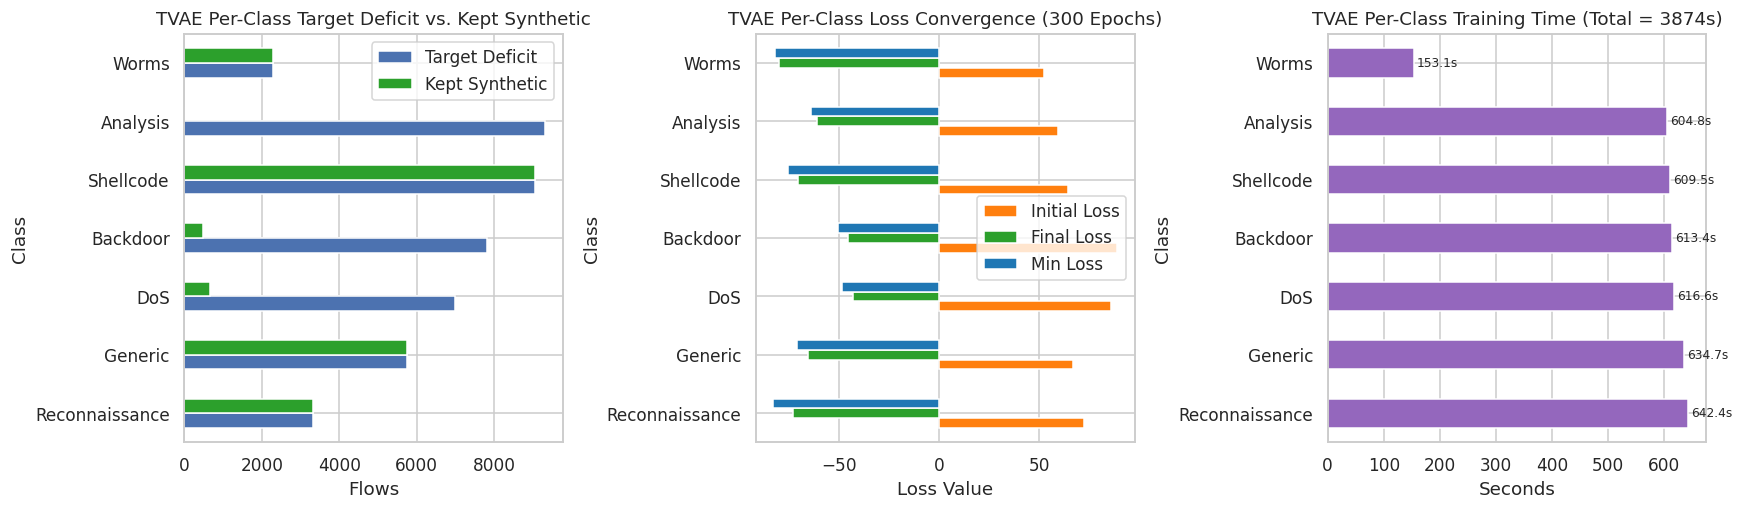

,Train Samples,Target Deficit,Kept Synthetic,Initial Loss,Final Loss,Min Loss,Elapsed (s)
Class,,,,,,,
Reconnaissance,10000,3327,3327,72.237450,-73.011978,-82.926010,642.37
Generic,10000,5739,5739,66.976387,-65.773819,-70.914986,634.73
DoS,10000,6990,664,85.962799,-42.881626,-48.535313,616.56
Backdoor,10000,7826,489,88.906883,-45.583118,-50.713757,613.39
Shellcode,10000,9055,9055,64.203346,-70.559189,-75.412407,609.53
Analysis,10000,9313,2,59.108746,-61.044846,-64.313194,604.76
Worms,2370,2291,2291,52.332302,-79.852470,-82.002235,153.12


,CTGAN (result_2),TVAE (result_2)
Kept Synthetic Flows,429.0000,21567.0000
Class Coverage (/9),5.0000,7.0000
Overall DFR,0.0097,0.4842
C2ST ROC-AUC (target ~0.50),1.0000,0.9999
Mean Categorical TVD,0.3254,0.2172
Mean Continuous KS,0.2653,0.1533
Mean Norm Wasserstein,0.0219,0.0182
Generative Precision,0.2191,0.5297
Generative Recall,0.4820,0.4960
PFIR Strict Pass Rate,0.0839,0.0911


In [15]:
# Section 14: Per-Class TVAE Training Diagnostics & Consolidated Scorecard
tvae_diag = tvae_summary["best_parameters"]["round2_generator_best_params"]["diagnostics"]
tvae_kept_counts = tvae_syn["Attack"].value_counts()

diag_rows = []
for cls_name, d in tvae_diag.items():
    diag_rows.append({
        "Class": cls_name,
        "Train Samples": d["samples"],
        "Target Deficit": d["syn_deficit"],
        "Kept Synthetic": int(tvae_kept_counts.get(cls_name, 0)),
        "Initial Loss": d.get("initial_loss", np.nan),
        "Final Loss": d.get("final_loss", np.nan),
        "Min Loss": d.get("min_loss", np.nan),
        "Elapsed (s)": d["elapsed_sec"],
    })
tvae_diag_df = pd.DataFrame(diag_rows).set_index("Class")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

# Panel 1: Deficit vs Kept
tvae_diag_df[["Target Deficit", "Kept Synthetic"]].plot(kind="barh", ax=axes[0], color=["#4c72b0", SYN_COLORS["TVAE"]])
axes[0].set_title("TVAE Per-Class Target Deficit vs. Kept Synthetic")
axes[0].set_xlabel("Flows")

# Panel 2: Initial vs Final vs Min Loss
tvae_diag_df[["Initial Loss", "Final Loss", "Min Loss"]].plot(kind="barh", ax=axes[1], color=["#ff7f0e", "#2ca02c", "#1f77b4"])
axes[1].set_title("TVAE Per-Class Loss Convergence (300 Epochs)")
axes[1].set_xlabel("Loss Value")

# Panel 3: Training Time
tvae_diag_df["Elapsed (s)"].plot(kind="barh", ax=axes[2], color="#9467bd")
axes[2].set_title(f"TVAE Per-Class Training Time (Total = {tvae_diag_df['Elapsed (s)'].sum():.0f}s)")
axes[2].set_xlabel("Seconds")
for container in axes[2].containers:
    axes[2].bar_label(container, fmt="%.1fs", fontsize=8, padding=2)

plt.tight_layout()
plt.show()
display(tvae_diag_df)

# Consolidated Scorecard
scorecard = pd.DataFrame({
    "CTGAN (result_2)": {
        "Kept Synthetic Flows": len(ctgan_syn),
        "Class Coverage (/9)": int((ctgan_syn["Attack"].value_counts() > 0).sum()),
        "Overall DFR": overall_dfr_map["CTGAN"],
        "C2ST ROC-AUC (target ~0.50)": c2st_results["CTGAN"]["auc"],
        "Mean Categorical TVD": float(tvd_cmp["CTGAN"].mean()),
        "Mean Continuous KS": float(ks_cmp["CTGAN"].mean()),
        "Mean Norm Wasserstein": float(wn_cmp["CTGAN"].mean()),
        "Generative Precision": float(pr_df.loc["CTGAN", "Precision"]),
        "Generative Recall": float(pr_df.loc["CTGAN", "Recall"]),
        "PFIR Strict Pass Rate": pfir_map["CTGAN"],
        "Holdout Macro F1": ctgan_summary["holdout_performance"]["macro_f1"],
        "Holdout T2 Rare F1": ctgan_summary["holdout_performance"]["t2_rare_f1"],
        "Holdout E2E Rare Recall": ctgan_summary["holdout_performance"]["e2e_rare_recall"],
        "Holdout FAR": ctgan_summary["holdout_performance"]["false_alarm_rate"],
    },
    "TVAE (result_2)": {
        "Kept Synthetic Flows": len(tvae_syn),
        "Class Coverage (/9)": int((tvae_syn["Attack"].value_counts() > 0).sum()),
        "Overall DFR": overall_dfr_map["TVAE"],
        "C2ST ROC-AUC (target ~0.50)": c2st_results["TVAE"]["auc"],
        "Mean Categorical TVD": float(tvd_cmp["TVAE"].mean()),
        "Mean Continuous KS": float(ks_cmp["TVAE"].mean()),
        "Mean Norm Wasserstein": float(wn_cmp["TVAE"].mean()),
        "Generative Precision": float(pr_df.loc["TVAE", "Precision"]),
        "Generative Recall": float(pr_df.loc["TVAE", "Recall"]),
        "PFIR Strict Pass Rate": pfir_map["TVAE"],
        "Holdout Macro F1": tvae_summary["holdout_performance"]["macro_f1"],
        "Holdout T2 Rare F1": tvae_summary["holdout_performance"]["t2_rare_f1"],
        "Holdout E2E Rare Recall": tvae_summary["holdout_performance"]["e2e_rare_recall"],
        "Holdout FAR": tvae_summary["holdout_performance"]["false_alarm_rate"],
    },
})
display(scorecard.round(4))